In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 6)

import warnings
warnings.filterwarnings('ignore')

## 1. Load the dataset

In [3]:
df = pd.read_csv('data.csv')
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


## 2. Exploratory Data Analysis (EDA)

In [6]:
# missing values
missing = df.isnull().sum().sort_values(ascending=False)
pd.DataFrame({'missing_count': missing[missing > 0]})

,missing_count
Cabin,687
Age,177
Embarked,2


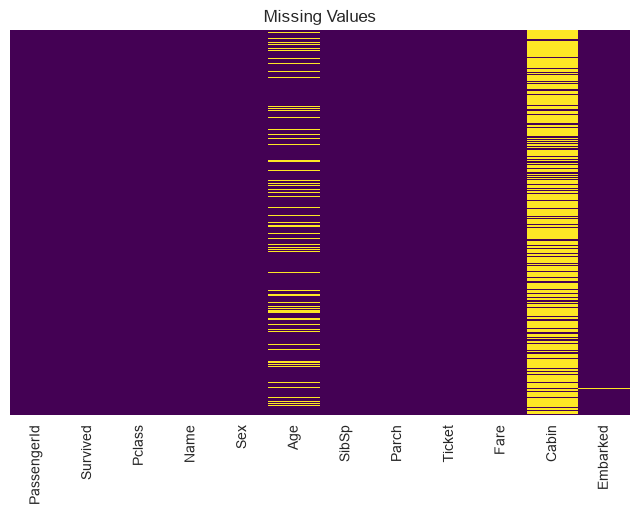

In [ ]:
# visualize missing values
plt.figure(figsize=(8, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False,
            cmap='viridis')
plt.title('Missing Values')
plt.show()

The heatmap visualizes the distribution of missing values in the dataset. It shows that Age contains several missing values, Cabin has a substantial amount of missing data, and Embarked has only one missing value.

In [29]:
#check for duplicates
df.duplicated().sum()

np.int64(0)

### Univariate Analysis

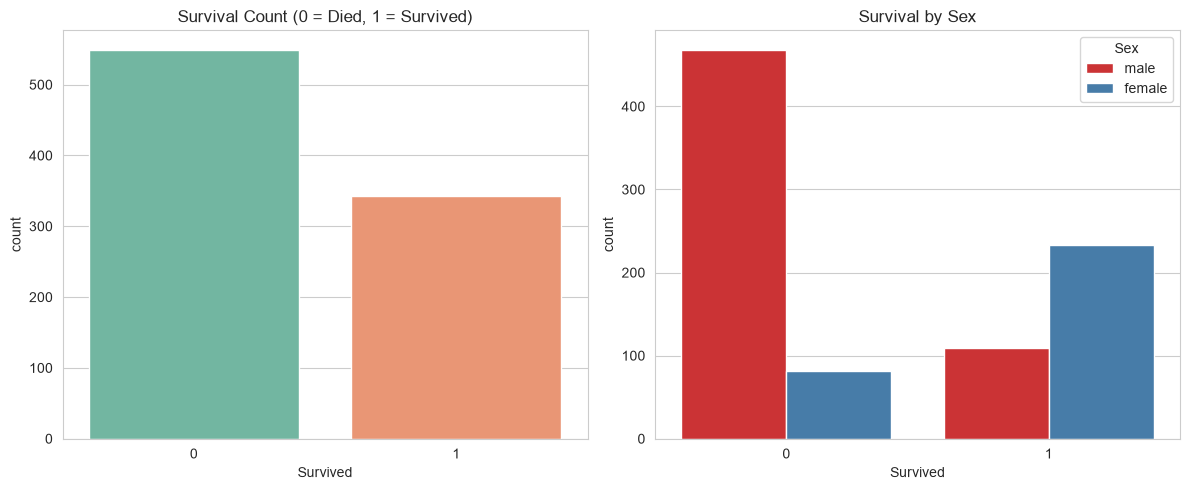

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='Survived', ax=ax[0], palette='Set2')
ax[0].set_title('Survival Count (0 = Died, 1 = Survived)')

sns.countplot(x='Survived', hue='Sex', data=df, ax=ax[1], palette='Set1')
ax[1].set_title('Survival by Sex')

plt.tight_layout()
plt.show()

The first plot shows that more passengers died than survived, indicating an imbalance in the target variable. The second plot shows that more females survived than males, while a larger number of males died. This suggests that sex may be an important feature for predicting passenger survival.

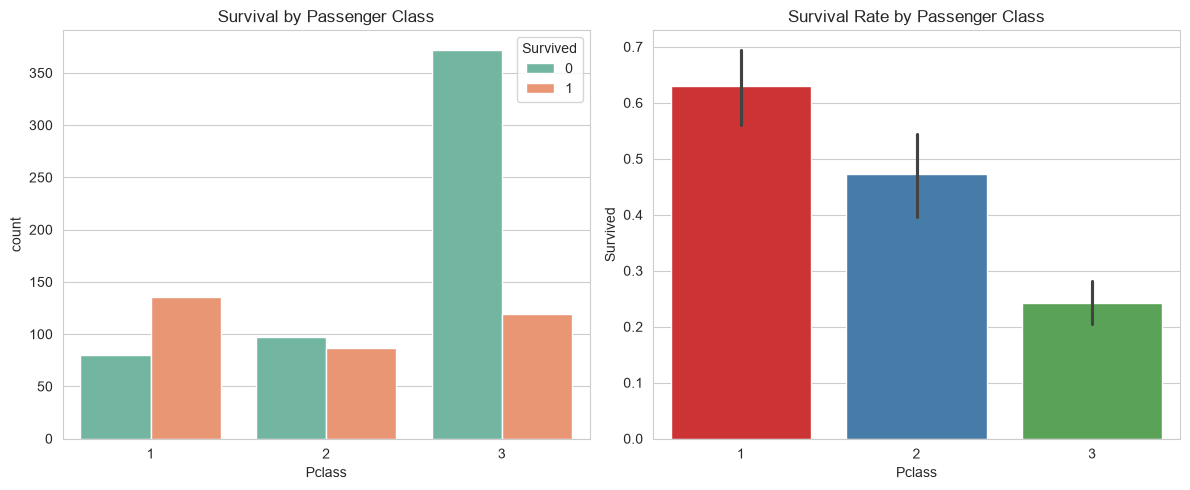

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='Pclass', hue='Survived',
              palette='Set2', ax=ax[0])
ax[0].set_title('Survival by Passenger Class')

sns.barplot(data=df, x='Pclass', y='Survived',
            palette='Set1', ax=ax[1])
ax[1].set_title('Survival Rate by Passenger Class')

plt.tight_layout()
plt.show()

The first plot shows the number of survivors and non-survivors across the three passenger classes. The second plot shows that first-class passengers had the highest survival rate, while third-class passengers had the lowest.

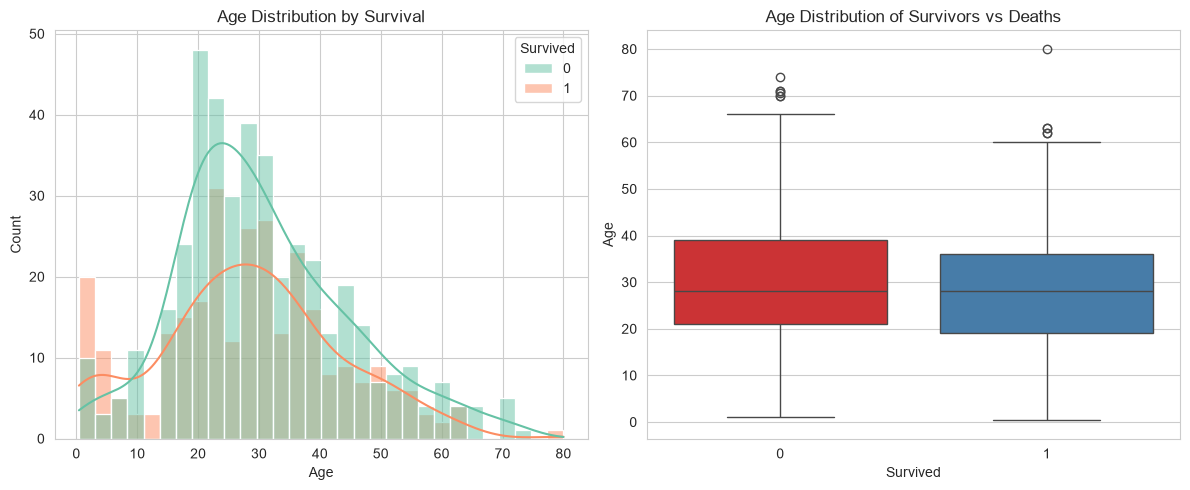

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=df, x='Age', hue='Survived',
             bins=30, kde=True, palette='Set2',
             ax=ax[0])
ax[0].set_title('Age Distribution by Survival')

sns.boxplot(data=df, x='Survived', y='Age',
            palette='Set1', ax=ax[1])
ax[1].set_title('Age Distribution of Survivors vs Deaths')

plt.tight_layout()
plt.show()

The histogram shows the age distribution of passengers who survived and those who died, with many passengers concentrated between 20 and 30 years. The boxplot compares the age distributions of both groups and shows an older passenger, approximately 80 years old, who survived. This suggests that age may provide useful information for predicting survival, although the distributions overlap.

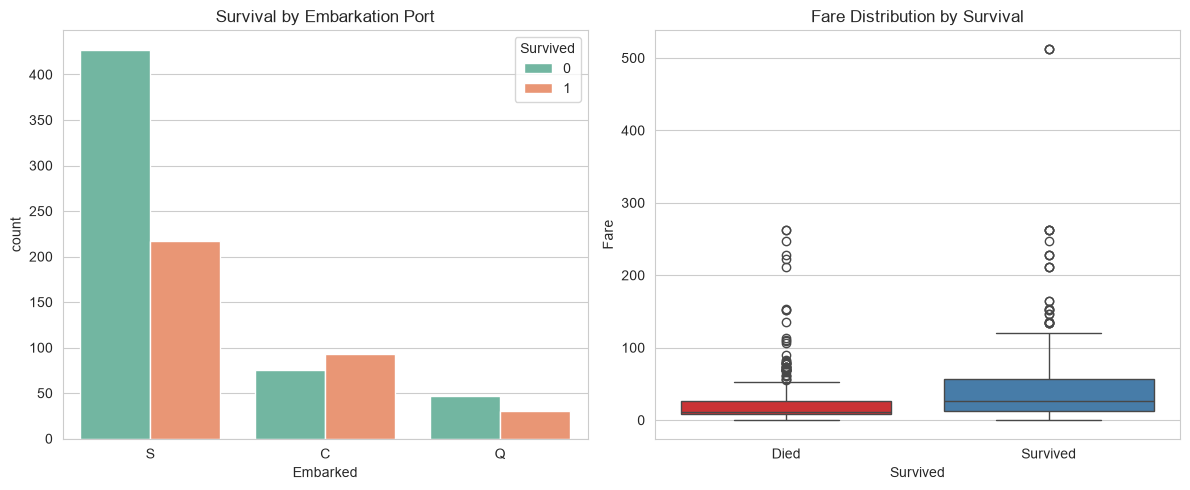

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='Embarked', hue='Survived',
              palette='Set2', ax=ax[0])
ax[0].set_title('Survival by Embarkation Port')

sns.boxplot(data=df, x='Survived', y='Fare',
            hue='Survived', palette='Set1',
            legend=False, ax=ax[1])
ax[1].set_title('Fare Distribution by Survival')
ax[1].set_xticks([0, 1], ['Died', 'Survived'])

plt.tight_layout()
plt.show()

The first plot shows that passengers who embarked at Cherbourg (C) had a higher proportion of survivors relative to deaths, while Southampton (S) had the largest number of passengers and deaths. The second plot shows that survivors generally paid higher fares than non-survivors, although both groups contain outliers. These observations suggest that embarkation port and fare may provide useful information for predicting survival.

### Bivariate Analysis

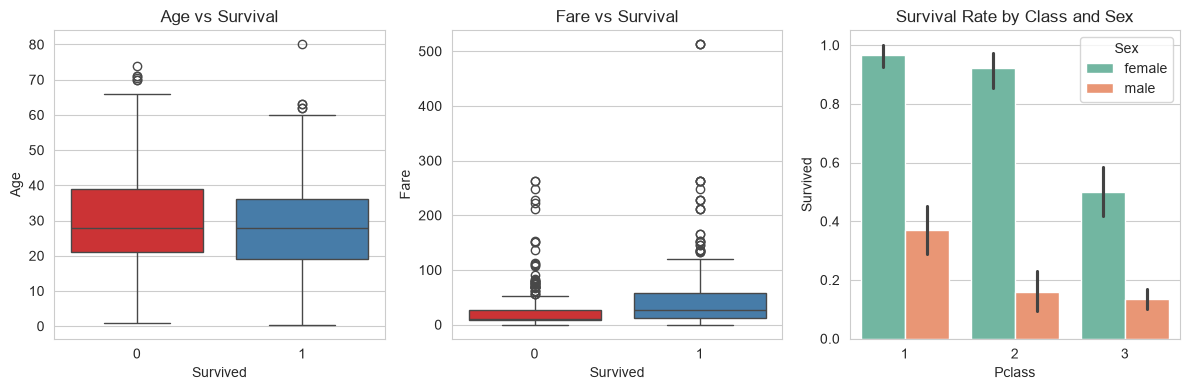

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sns.boxplot(data=df, x='Survived', y='Age',
            hue='Survived', palette='Set1',
            legend=False, ax=axes[0])
axes[0].set_title('Age vs Survival')

sns.boxplot(data=df, x='Survived', y='Fare',
            hue='Survived', palette='Set1',
            legend=False, ax=axes[1])
axes[1].set_title('Fare vs Survival')

sns.barplot(data=df, x='Pclass', y='Survived',
            hue='Sex', palette='Set2', ax=axes[2])
axes[2].set_title('Survival Rate by Class and Sex')

plt.tight_layout()
plt.show()

The first boxplot compares passenger ages by survival status, showing overlapping age distributions between survivors and non-survivors. The second boxplot suggests that survivors generally paid higher fares, with several high-fare outliers.


The barplot shows survival rates by passenger class and sex, highlighting differences between male and female passengers across classes. These patterns suggest that age, fare, passenger class, and sex may be useful features for predicting survival.

## 3. Data cleaning & Feature engineering

Steps Taken: 

- Extract passenger titles from the `Name` column.
- Group rare titles and standardize similar titles.
- Handle missing `Age` values using title-based median imputation.
- Fill missing `Embarked` values using the mode.
- Fill missing `Fare` values using the median.
- Create `FamilySize` by combining `SibSp` and `Parch`.
- Create `IsAlone` to identify passengers travelling alone.
- Categorize passengers into age groups using `AgeGroup`.
- Drop irrelevant or redundant columns, including `PassengerId`, `Ticket`, `Cabin`, and `Name`.


In [55]:
data = df.copy()

In [56]:
# Extract titles (Mr, Mrs, Miss, Master, etc.) from passenger names
data['Title'] = data['Name'].str.extract(r',\s*([^\.]+)\.', expand=False)

# Group uncommon titles into a single category to reduce rare categories
data['Title'] = data['Title'].replace(
    ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr',
     'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'],
    'Rare'
)

# Standardize equivalent titles
data['Title'] = data['Title'].replace({
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs'
})

In [57]:
# Fill missing ages using the median age for each title group
data['Age'] = data.groupby('Title')['Age'].transform(
    lambda x: x.fillna(x.median())
)

# Fill any remaining missing ages using the overall median
data['Age'] = data['Age'].fillna(data['Age'].median())

In [60]:
# Fill missing Embarked values with the most frequent embarkation port
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

# Fill missing fares with the median fare
data['Fare'] = data['Fare'].fillna(data['Fare'].median())

In [61]:
# Calculate the total family size, including the passenger
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1

# Identify passengers travelling without listed family members
data['IsAlone'] = (data['FamilySize'] == 1).astype(int)

In [62]:
# Categorize passengers into age groups
data['AgeGroup'] = pd.cut(
    data['Age'],
    bins=[0, 12, 18, 35, 60, float('inf')],
    labels=['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']
)

In [65]:
# Remove the passenger identifier and columns excluded from this model
data.drop(
    columns=['PassengerId', 'Name', 'Ticket', 'Cabin'],
    inplace=True
)

In [83]:
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,AgeGroup
0,0,3,male,22.0,1,0,7.2500,S,Mr,2,0,Young Adult
1,1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,Adult
2,1,3,female,26.0,0,0,7.9250,S,Miss,1,1,Young Adult
3,1,1,female,35.0,1,0,53.1000,S,Mrs,2,0,Young Adult
4,0,3,male,35.0,0,0,8.0500,S,Mr,1,1,Young Adult


## 4. Data Preprocessing: Train-Test Split, Encoding and Feature Scaling

In [77]:
X = data.drop(columns=['Survived'])
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cat_cols = ['Sex', 'Embarked', 'Title', 'AgeGroup']

encoder = OneHotEncoder(
    handle_unknown='ignore',
    drop='first',
    sparse_output=False
)

X_train_cat = encoder.fit_transform(X_train[cat_cols])
X_test_cat = encoder.transform(X_test[cat_cols])

X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=encoder.get_feature_names_out(cat_cols),
    index=X_train.index
)
X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=encoder.get_feature_names_out(cat_cols),
    index=X_test.index
)

In [82]:
num_cols = X_train.select_dtypes(include=['number']).columns
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train[num_cols])
X_test_scaled = scaler.transform(X_test[num_cols])

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (712, 11)  Test shape: (179, 11)


In [84]:
# Scaled data
X_train_scaled_final = pd.concat([
    pd.DataFrame(X_train_scaled, columns=num_cols, index=X_train.index),
    X_train_cat
], axis=1)

X_test_scaled_final = pd.concat([
    pd.DataFrame(X_test_scaled, columns=num_cols, index=X_test.index),
    X_test_cat
], axis=1)

# Unscaled data
X_train_unscaled_final = pd.concat([
    X_train[num_cols],
    X_train_cat
], axis=1)

X_test_unscaled_final = pd.concat([
    X_test[num_cols],
    X_test_cat
], axis=1)

## 5. Model  Training & Evaluation

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in models.items():

    if name in ['Logistic Regression', 'KNN']:
        X_train_eval = X_train_scaled_final
        X_eval = X_test_scaled_final
    else:
        X_train_eval = X_train_unscaled_final
        X_eval = X_test_unscaled_final

    # 5-fold cross-validation on training data
    cv_scores = cross_val_score(
        model,
        X_train_eval,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    model.fit(X_train_eval, y_train)

    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]

    # Store evaluation metrics
    results.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'CV Mean Accuracy': cv_scores.mean(),
        'CV Std': cv_scores.std()
    })

results_df = pd.DataFrame(results)

results_df.round(3)

,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Mean Accuracy,CV Std
0,Logistic Regression,0.849,0.828,0.768,0.797,0.878,0.816,0.019
1,KNN,0.816,0.790,0.710,0.748,0.862,0.803,0.036
2,Decision Tree,0.810,0.769,0.725,0.746,0.788,0.768,0.016
3,Random Forest,0.810,0.761,0.739,0.750,0.824,0.803,0.010


## 6. Model Comparison

In [93]:
results_df.sort_values(
    by='F1-Score',
    ascending=False
).round(3)

,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Mean Accuracy,CV Std
0,Logistic Regression,0.849,0.828,0.768,0.797,0.878,0.816,0.019
3,Random Forest,0.810,0.761,0.739,0.750,0.824,0.803,0.010
1,KNN,0.816,0.790,0.710,0.748,0.862,0.803,0.036
2,Decision Tree,0.810,0.769,0.725,0.746,0.788,0.768,0.016


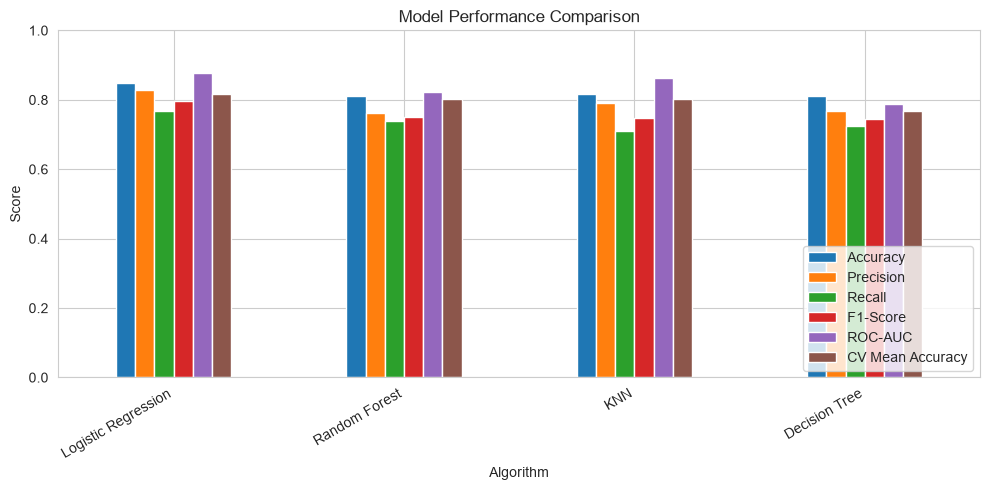

In [99]:
results_df.set_index('Algorithm')[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC',
     'CV Mean Accuracy']
].plot(kind='bar', figsize=(10, 5))

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Algorithm')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 7. Best Model Evaluation

The best-performing model is selected based on its F1-score, cross-validation performance, and overall test-set metrics. Its predictions are then examined using a confusion matrix and classification report.

In [ ]:
results_df = results_df.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

best_model_name = results_df.loc[0, 'Algorithm']
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("\nClassification Report:")
print(classification_report(y_test, best_model.predict(
    X_test_scaled_final if best_model_name in ['Logistic Regression', 'KNN']
    else X_test_unscaled_final
)))

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88       110
           1       0.83      0.77      0.80        69

    accuracy                           0.85       179
   macro avg       0.84      0.83      0.84       179
weighted avg       0.85      0.85      0.85       179



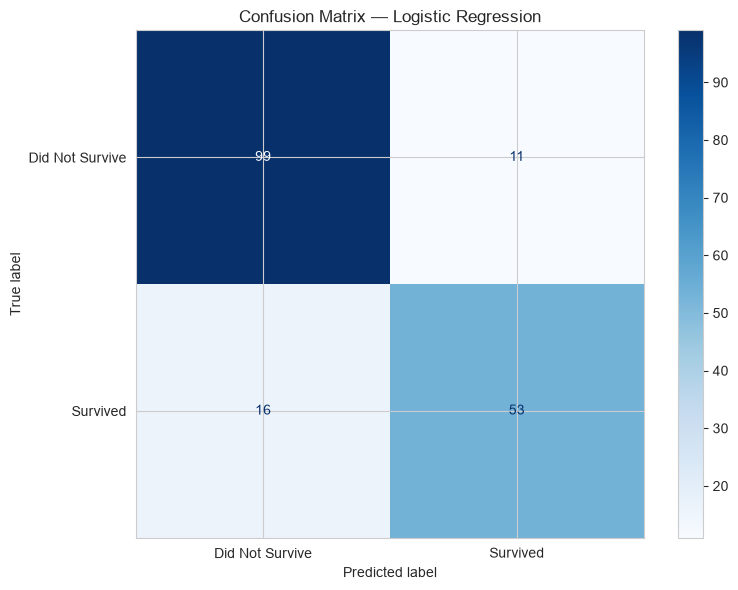

In [96]:
ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test_scaled_final if best_model_name in ['Logistic Regression', 'KNN']
    else X_test_unscaled_final,
    y_test,
    display_labels=['Did Not Survive', 'Survived'],
    cmap='Blues'
)

plt.title(f'Confusion Matrix — {best_model_name}')
plt.tight_layout()
plt.show()

## 8. Saving the Best Model

In [97]:
import joblib

joblib.dump(best_model, 'best_titanic_model.pkl')


['best_titanic_model.pkl']

In [98]:
joblib.dump(encoder, 'titanic_encoder.pkl')
joblib.dump(scaler, 'titanic_scaler.pkl')

['titanic_scaler.pkl']

## 9. Conclusion

This project developed and evaluated machine learning classification models to predict passenger survival on the Titanic dataset.

Four algorithms were compared: Logistic Regression, K-Nearest Neighbors, Decision Tree, and Random Forest. Their performance was assessed using accuracy, precision, recall, F1-score, ROC-AUC, and five-fold cross-validation.

The best-performing model was selected based on its evaluation metrics and examined further using a confusion matrix and classification report. The selected model was then saved for future use.

This project provided practical experience in data preprocessing, feature engineering, categorical encoding, feature scaling, model training, cross-validation, model evaluation, and model persistence.

The results are specific to this dataset and evaluation setup; performance on unseen data may differ.